# Transformer로 분석하는 조선 여성교육 텍스트의 의미적 중요도

**종교교육학·텍스트 분석 수업용 Jupyter Notebook**

학습 목표: (1) 빈도와 문맥 관련성 구별 (2) 한국어 Transformer 임베딩 생성 (3) 문장·핵심 표현의 전체 텍스트에 대한 코사인 유사도 계산 (4) 결과 해석의 한계 이해.

> **중요:** 이 실습의 점수는 객관적인 역사적 중요도나 인과관계가 아닙니다. 선택한 사전학습 모델의 임베딩 공간에서 **전체 문맥과의 의미적 관련성**을 측정합니다. Attention 가중치를 직접 중요도로 해석하지 않습니다. 원문이 매우 짧으므로 순위는 탐색적으로 해석합니다.

**실행:** VS Code Jupyter 또는 JupyterLab. 최초 실행 시 패키지 설치 및 Hugging Face 모델 다운로드를 위해 인터넷 연결이 필요합니다. CPU에서도 실행할 수 있습니다.

## 1. 라이브러리 설치
처음 한 번만 실행합니다. 설치 후 커널 재시작이 필요할 수 있습니다.

In [1]:
%pip install -q torch transformers sentence-transformers pandas numpy matplotlib seaborn scikit-learn wordcloud

Note: you may need to restart the kernel to use updated packages.


## 2. 원문 입력과 분석 단위 설정
문장 단위는 수업용으로 연구자가 분절했습니다. 의미 분석 결과는 분절 방식에 따라 달라질 수 있습니다.

In [2]:
sentences = [
    "선교사들이 빅토리아 가치관으로 한국 여성을 가르치려 했는데,",
    "한국 여성의 지위와 상황이 상대적으로 더 열약하다보니,",
    "그것을 일깨워주기 위해 교육을 했고 (우리는 이 정도는 아니다. 서양에서는 이정도이다)",
    "그것이 도화선이 되었다.",
    "언더우드 여사의 시대적 가치관이 한국 여성에게 영향을 주었다.",
    "학당이나 교회라는 교육 장소가 생기고, 그로 인해 가치관의 혁명이 발생"
]
text = " ".join(sentences)
for i, s in enumerate(sentences, 1):
    print(f"{i}. {s}")

1. 선교사들이 빅토리아 가치관으로 한국 여성을 가르치려 했는데,
2. 한국 여성의 지위와 상황이 상대적으로 더 열약하다보니,
3. 그것을 일깨워주기 위해 교육을 했고 (우리는 이 정도는 아니다. 서양에서는 이정도이다)
4. 그것이 도화선이 되었다.
5. 언더우드 여사의 시대적 가치관이 한국 여성에게 영향을 주었다.
6. 학당이나 교회라는 교육 장소가 생기고, 그로 인해 가치관의 혁명이 발생


## 3. 한국어를 지원하는 다국어 Sentence Transformer 불러오기
`paraphrase-multilingual-MiniLM-L12-v2`는 한국어를 포함하는 다국어 문장 임베딩 모델입니다. 모델이 내부적으로 Transformer의 Self-Attention을 사용합니다. GPU가 없으면 CPU를 사용합니다.

In [3]:
import torch
from sentence_transformers import SentenceTransformer

MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("실행 장치:", device)
model = SentenceTransformer(MODEL_NAME, device=device)
print("모델 로딩 완료")

실행 장치: cpu


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

모델 로딩 완료


## 4. 문장 임베딩 및 전체 문맥과의 유사도
전체 문맥 벡터는 문장 임베딩의 평균으로 정의합니다. 자기 자신이 평균에 포함되어 유사도가 높아지는 효과를 줄이기 위해, 각 문장을 제외한 나머지 문장의 평균과 비교하는 **Leave-One-Out(LOO) 유사도**도 함께 계산합니다. LOO 점수를 주된 탐색 지표로 사용합니다.

In [4]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

emb = model.encode(sentences, convert_to_numpy=True, normalize_embeddings=True)
context = emb.mean(axis=0, keepdims=True)
context /= np.linalg.norm(context, axis=1, keepdims=True)
whole_scores = cosine_similarity(emb, context).ravel()

loo_scores = []
for i in range(len(sentences)):
    others = np.delete(emb, i, axis=0).mean(axis=0, keepdims=True)
    others /= np.linalg.norm(others, axis=1, keepdims=True)
    loo_scores.append(float(cosine_similarity(emb[i:i+1], others)[0, 0]))

sentence_results = pd.DataFrame({
    "문장번호": np.arange(1, len(sentences)+1),
    "문장": sentences,
    "전체문맥_유사도": whole_scores,
    "LOO_문맥유사도": loo_scores
}).sort_values("LOO_문맥유사도", ascending=False)
display(sentence_results.round(4))

,문장번호,문장,전체문맥_유사도,LOO_문맥유사도
0,1,"선교사들이 빅토리아 가치관으로 한국 여성을 가르치려 했는데,",0.7155,0.5409
4,5,언더우드 여사의 시대적 가치관이 한국 여성에게 영향을 주었다.,0.6598,0.4639
1,2,"한국 여성의 지위와 상황이 상대적으로 더 열약하다보니,",0.6585,0.4621
2,3,그것을 일깨워주기 위해 교육을 했고 (우리는 이 정도는 아니다. 서양에서는 이정도이다),0.6322,0.4271
5,6,"학당이나 교회라는 교육 장소가 생기고, 그로 인해 가치관의 혁명이 발생",0.6254,0.4180
3,4,그것이 도화선이 되었다.,0.4634,0.2171


## 5. 문장 간 의미 유사도 히트맵

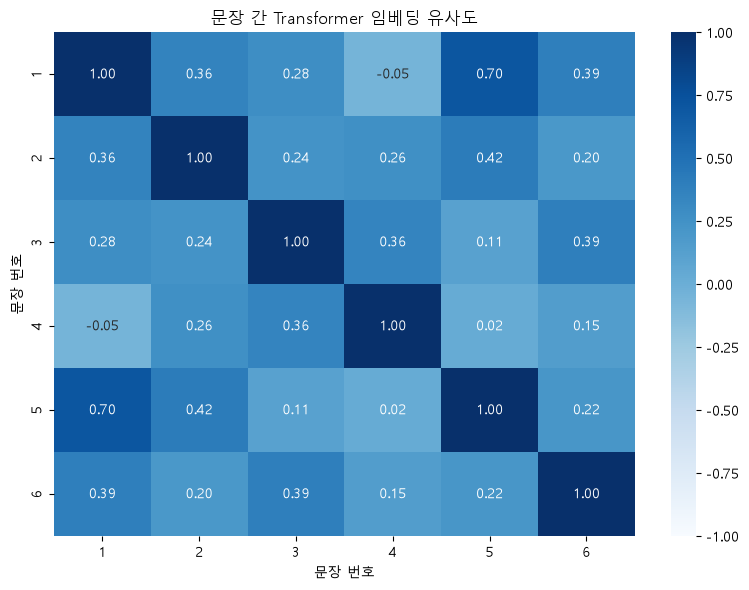

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager

# Windows 맑은 고딕 우선, 없으면 사용 가능한 한글 폰트 탐색
font_names = {f.name for f in font_manager.fontManager.ttflist}
for candidate in ["Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "AppleGothic"]:
    if candidate in font_names:
        plt.rcParams["font.family"] = candidate
        break
plt.rcParams["axes.unicode_minus"] = False

sim = cosine_similarity(emb)
plt.figure(figsize=(8, 6))
sns.heatmap(sim, annot=True, fmt=".2f", cmap="Blues", xticklabels=range(1,7), yticklabels=range(1,7), vmin=-1, vmax=1)
plt.title("문장 간 Transformer 임베딩 유사도")
plt.xlabel("문장 번호"); plt.ylabel("문장 번호")
plt.tight_layout(); plt.show()

## 6. 문장별 문맥 관련성 막대그래프

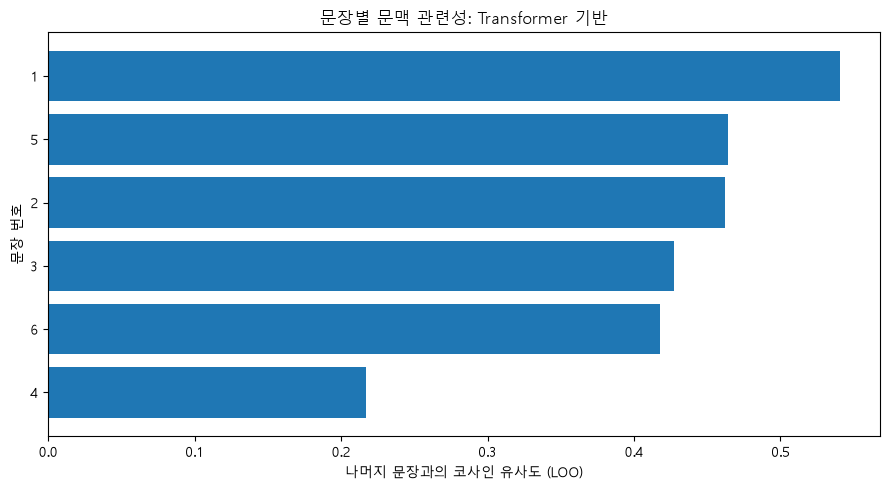

In [6]:
plot_df = sentence_results.sort_values("LOO_문맥유사도")
plt.figure(figsize=(9, 5))
plt.barh(plot_df["문장번호"].astype(str), plot_df["LOO_문맥유사도"])
plt.xlabel("나머지 문장과의 코사인 유사도 (LOO)")
plt.ylabel("문장 번호")
plt.title("문장별 문맥 관련성: Transformer 기반")
plt.tight_layout(); plt.show()

## 7. 핵심 표현의 문맥 관련성
한국어 서브워드 토큰을 그대로 워드클라우드에 넣으면 어색한 조각이 나올 수 있습니다. 따라서 **연구자가 원문에서 지정한 핵심 표현**을 모델에 입력하여, 전체 텍스트 임베딩과의 유사도를 계산합니다. 이는 표현의 *문맥 관련성*이지 원문 안에서 해당 표현이 갖는 토큰별 기여도는 아닙니다.

In [7]:
terms = [
    "선교사", "빅토리아 가치관", "한국 여성", "여성의 지위", "교육",
    "서양", "언더우드 여사", "시대적 가치관", "영향", "학당",
    "교회", "교육 장소", "가치관의 혁명", "도화선"
]
term_emb = model.encode(terms, convert_to_numpy=True, normalize_embeddings=True)
text_emb = model.encode([text], convert_to_numpy=True, normalize_embeddings=True)
term_scores = cosine_similarity(term_emb, text_emb).ravel()
term_results = pd.DataFrame({"핵심표현": terms, "문맥유사도": term_scores}).sort_values("문맥유사도", ascending=False)
display(term_results.round(4))

,핵심표현,문맥유사도
2,한국 여성,0.5305
12,가치관의 혁명,0.4462
3,여성의 지위,0.3996
1,빅토리아 가치관,0.3908
7,시대적 가치관,0.3630
11,교육 장소,0.3121
0,선교사,0.3040
4,교육,0.2947
9,학당,0.2728
10,교회,0.2425


## 8. 핵심 표현 관련성 시각화

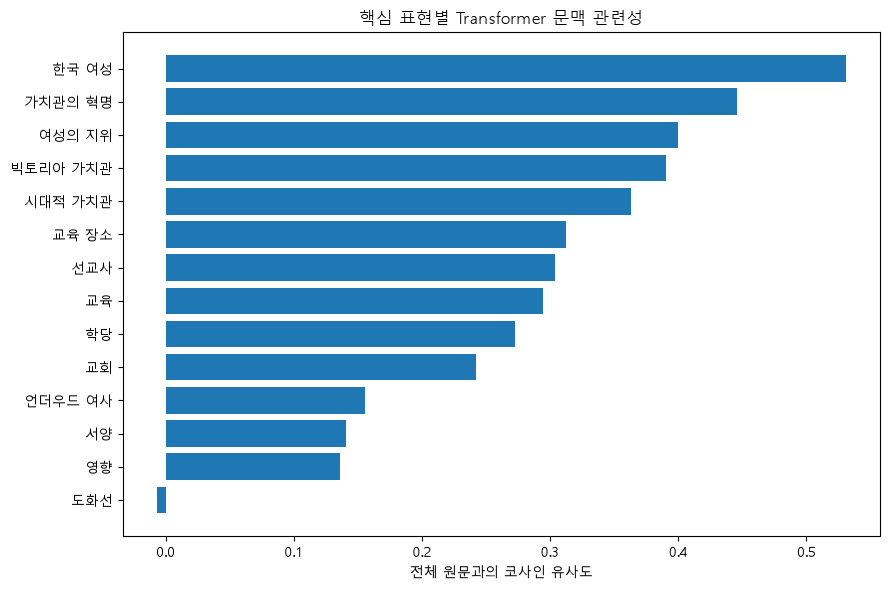

In [8]:
plot_terms = term_results.sort_values("문맥유사도")
plt.figure(figsize=(9, 6))
plt.barh(plot_terms["핵심표현"], plot_terms["문맥유사도"])
plt.xlabel("전체 원문과의 코사인 유사도")
plt.title("핵심 표현별 Transformer 문맥 관련성")
plt.tight_layout(); plt.show()

## 9. 문맥 관련성 기반 워드클라우드
표현의 크기는 출현 횟수가 아닌 문맥 유사도에 비례합니다. 코사인 유사도는 음수일 수 있으므로 시각화를 위해 0~1 구간으로 변환합니다. **그림의 크기는 시각화용 변환 점수**입니다.

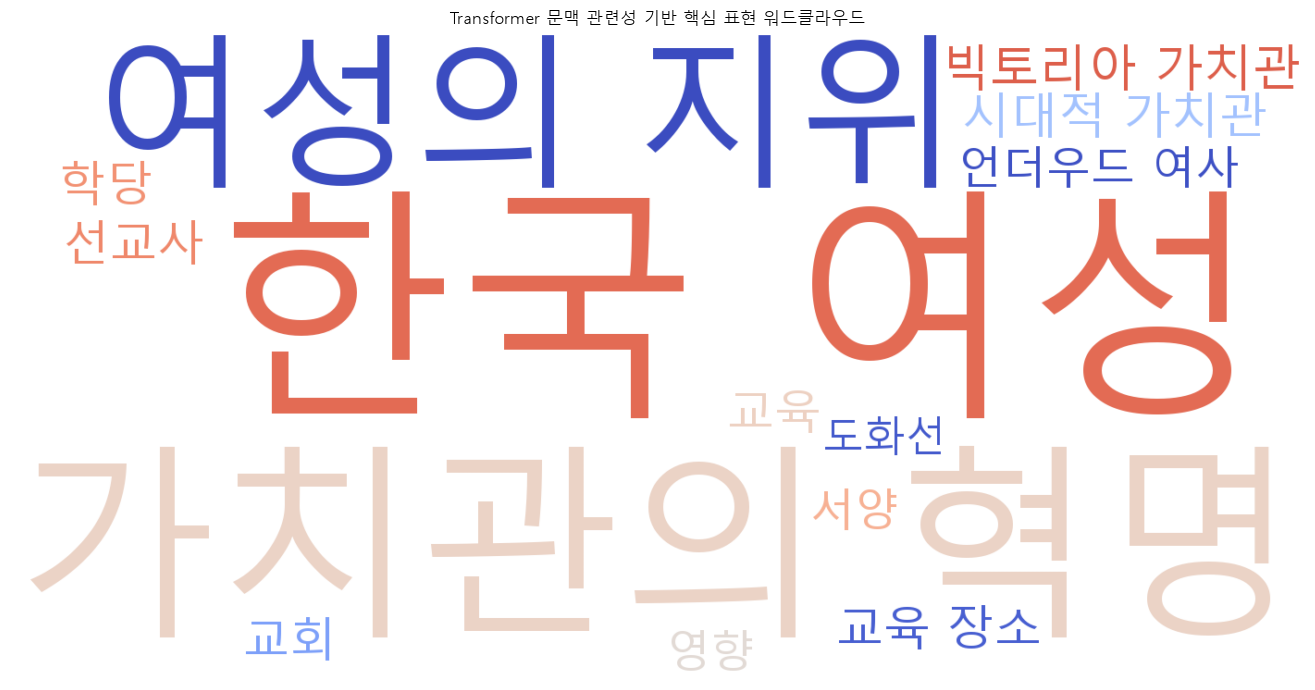

In [9]:
from wordcloud import WordCloud
from pathlib import Path

# Windows 기본 한글 글꼴 경로; 다른 OS에서는 경로 수정
font_candidates = [
    Path("C:/Windows/Fonts/malgun.ttf"),
    Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf"),
    Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
]
font_path = next((str(p) for p in font_candidates if p.exists()), None)
if font_path is None:
    raise FileNotFoundError("한글 폰트 경로를 확인하고 font_candidates를 수정하세요.")

# 순위를 표시할 수 있도록 양수 가중치로 변환
weights = {row["핵심표현"]: max(0.01, (float(row["문맥유사도"])+1)/2)
           for _, row in term_results.iterrows()}
wc = WordCloud(font_path=font_path, width=1400, height=700,
               background_color="white", colormap="coolwarm",
               prefer_horizontal=1.0, collocations=False,
               random_state=123, margin=6).generate_from_frequencies(weights)
plt.figure(figsize=(14, 7))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Transformer 문맥 관련성 기반 핵심 표현 워드클라우드")
plt.tight_layout(); plt.show()

## 10. 결과 저장

In [10]:
from pathlib import Path
out = Path("transformer_missionary_results")
out.mkdir(exist_ok=True)
sentence_results.to_csv(out / "sentence_semantic_scores.csv", index=False, encoding="utf-8-sig")
term_results.to_csv(out / "term_semantic_scores.csv", index=False, encoding="utf-8-sig")
wc.to_file(str(out / "semantic_wordcloud.png"))
print("저장 폴더:", out.resolve())

저장 폴더: C:\Users\손문\Documents\2026_2학기 교대원_커뮤니케이션과 종교교육\제6주_커뮤니케이션과 시스템이론\transformer_missionary_results


## 11. 해석 및 토론

1. 단어 빈도가 높은 표현과 문맥 유사도가 높은 표현은 같은가?
2. 왜 한 문장이 다른 문장들과 유사하다고 해서 역사적으로 가장 중요하다고 결론 내릴 수 없는가?
3. '학당', '교회', '가치관의 혁명' 사이의 인과관계를 확인하려면 어떤 사료가 추가로 필요한가?
4. 문장 분절 방식과 핵심 표현 목록을 바꾸면 순위가 어떻게 달라지는가?
5. 동일한 데이터를 다른 한국어 문장 임베딩 모델로 분석하면 결과가 안정적인가?

**연구상 주의:** 짧은 단일 문서의 임베딩 유사도는 통계적 유의성이나 역사적 사실 검증을 제공하지 않습니다. 핵심 표현 목록은 연구자가 정했으므로 선택 편향이 있습니다. 원문 내 개별 토큰의 중요도를 검증하려면 마스킹 기반 점수 변화, 여러 모델 비교, 전문가 평가 등의 별도 설계가 필요합니다.